### **Configuração Pasta Raiz**

In [1]:
import sys
import os

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))

# Adiciona a raiz do projeto ao path do Python para que as importações funcionem
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# print(f"Raiz do projeto definida como: {PROJECT_ROOT}")

In [2]:
import pandas as pd                                                                # Manipulação de dados
import numpy as np                                                                 # Realização de cálculos específicos
import matplotlib.pyplot as plt                                                    # Visualização de dados 
import seaborn as sns                                                              # Visualização de dados
import time                                                                        # Cálculo de tempo de execução
import math                                                                        # Funções matemáticas
from scipy.stats import randint, uniform, loguniform                               # Geração de valores aleatórios
from sklearn.compose import ColumnTransformer                                      # Transformação de colunas
from sklearn.preprocessing import StandardScaler, OneHotEncoder                    # Transformação de colunas
from sklearn.base import clone                                                     # Criação de cópias de modelos
from sklearn.model_selection import train_test_split                               # Validação simples
from imblearn.under_sampling import RandomUnderSampler                             # Subamostragem
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV            # Validação cruzada e estratificação de folds
from sklearn.utils.class_weight import compute_sample_weight                       # Cálculo de pesos para observações
from sklearn.linear_model import SGDClassifier                                     # Regressão logística com regularização
from sklearn.tree import DecisionTreeClassifier                                    # Árvore de decisão
from sklearn.ensemble import RandomForestClassifier                                # Floresta aleatória
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier        # Impulsionamento tradicional
from sklearn.ensemble import HistGradientBoostingClassifier                        # Impulsionamento com histogramas
from xgboost import XGBClassifier                                                  # Impulsionamento via XGBoost
from lightgbm import LGBMClassifier                                                # Impulsionamento via LightGBM
from sklearn.calibration import CalibratedClassifierCV                             # Calibração de probabilidades
from sklearn.calibration import calibration_curve                                  # Gráfico de curva de calibração
from sklearn.metrics import brier_score_loss                                       # Score de Brier
from sklearn.preprocessing import label_binarize                                   # Binarização da resposta (Score de Brier one-vs-rest)
from sklearn.metrics import confusion_matrix                                       # Análise de desempenho: matriz de classificação
from sklearn.metrics import accuracy_score, balanced_accuracy_score                # Análise de desempenho: acurácia e acurácia balanceada
from sklearn.metrics import get_scorer, auc, roc_auc_score, roc_curve              # Análise de desempenho: KS e AUC
from sklearn.inspection import permutation_importance                              # Importância de variáveis por permutação
import shap                                                                        # Interpretabilidade de variáveis nos modelos

### **Leitura da base de dados**

In [3]:
FILES = {
    'all_players': "data/01_final_dataset_merged.csv",
    'college_players': "data/02_college_players_dataset.csv",
    'college_players_before_2021': "data/03_college_players_before_2021_dataset.csv",
    'college_players_after_2021': "data/04_college_players_after_2021_dataset.csv",
    'college_players_after_2021_dropped': "data/05_college_players_after_2021_dropped_dataset.csv",
    'final': "data/00_final_dataset.csv"
}

In [4]:
dfs = {}

for key, filename in FILES.items():
    file_path = f'../{filename}'
    
    try:
        dfs[key] = pd.read_csv(file_path)
        
        print(f"✅ {key.ljust(15)}: Carregado ({len(dfs[key])} linhas)")
        
    except FileNotFoundError:
        print(f"❌ {key.ljust(15)}: Arquivo não encontrado em '{file_path}'")
    except Exception as e:
        print(f"❌ {key.ljust(15)}: Erro - {e}")

✅ all_players    : Carregado (1542 linhas)
✅ college_players: Carregado (1183 linhas)
✅ college_players_before_2021: Carregado (954 linhas)
✅ college_players_after_2021: Carregado (229 linhas)
✅ college_players_after_2021_dropped: Carregado (229 linhas)
✅ final          : Carregado (954 linhas)


In [5]:
dados = dfs['final'].copy()

### **Etapa 1: Especificação de variáveis**

*Lista de nomes das variáveis explicativas, separando em quantitativas e qualitativas*

In [6]:
# Variáveis explicativas quantitativas (deixar vazio [] caso não haja nenhuma)
lista_X_quanti = [
  # --- Informações Físicas e do Draft ---
    'draft_year', 
    'draft_age', 
    'years_college', 
    'mock_pick',        # Expectativa do mercado antes do draft
    'height_cm', 
    'weight_kg',

    # --- Estatísticas Avançadas (Eficiência) ---
    'true_shooting_pct', 
    'effective_field_goal_pct', 
    'usage_pct',
    'offensive_win_shares', 
    'defensive_win_shares', 
    'win_shares_per_40min',
    'three_point_attempt_rate', 
    'free_throw_attempt_rate',

    # --- Estatísticas de Arremesso (Volume e Precisão) ---
    'field_goal_attempted', 
    'three_pointers_made', 
    'three_pointers_attempted', 
    'three_point_pct',
    'free_throw_attempted', 
    'free_throw_pct',

    # --- Estatísticas Tradicionais (Médias por Jogo) ---
    'points', 
    'assists', 
    'total_rebounds', 
    'offensive_rebounds', 
    'defensive_rebounds',
    'steals', 
    'blocks', 
    'turnovers', 
    'personal_fouls',

    # --- Experiência no College (Acumulados) ---
    'career_games', 
    'career_starts', 
    'career_minutes', 
    'career_awards_count'
]

# Variáveis explicativas qualitativas (deixar vazio [] caso não haja nenhuma)
lista_X_quali = [
    # 'college_name', 
    # 'conference', 
    'position'
]

*Objetos para variável resposta (y) e explicativas (X)*

In [7]:
y = dados['target_label']
X = dados[lista_X_quali + lista_X_quanti]

In [8]:
# Ordenando as categorias da resposta y
ordem_categorias = ['Bust', 'Rotation', 'Starter', 'Star']
y = y.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True))

### **Etapa 2: Divisão de treino e teste externo**

*Divisão inicial*

In [9]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y,
                                                        test_size=0.2,
                                                        stratify=y,
                                                        random_state=123)

*Representação das categorias de y como números (requerido por alguns algoritmos e para calibração)*

In [10]:
y_treino = y_treino.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True)).cat.codes.rename(y.name)
y_teste = y_teste.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True)).cat.codes.rename(y.name)

In [11]:
y_treino.value_counts()

target_label
0    397
1    221
2    103
3     42
Name: count, dtype: int64

### **Etapa 3: Pré-processamento de variáveis explicativas**

*Definição das funções de pré-processamento: Padronização das variáveis quantitativas + Codificação one-hot para variáveis qualitativas*

In [12]:
preprocessador = ColumnTransformer(transformers=[
    # ERRO ANTERIOR: ("quanti", "passthrough", [lista_X_quanti]) <- Colchetes errados
    # CORRETO: ("quanti", "passthrough", lista_X_quanti)
    ("quanti", "passthrough", lista_X_quanti), 
    
    # Para as qualitativas, a lista também vai direta, sem colchetes extras
    ("quali", OneHotEncoder(sparse_output=False, drop="first", handle_unknown='ignore'), lista_X_quali)
],
    remainder="drop" 
)

*Criação do pré-processamento no conjunto de treino* <br>

In [13]:
X_treino_tratada = preprocessador.fit_transform(X_treino)  # O pré-processamento não deve envolver o conjunto de teste externo, que deve ficar reservado apenas para aplicações de resultados já obtidos, e nunca construções
if lista_X_quali:
    nomes_quali = list(preprocessador.named_transformers_['quali'].get_feature_names_out(lista_X_quali))
else:
    nomes_quali = []
nomes_variaveis = list(lista_X_quanti) + nomes_quali

In [14]:
X_treino_tratada = pd.DataFrame(X_treino_tratada, columns=nomes_variaveis)
X_treino_tratada.head()

,draft_year,draft_age,years_college,mock_pick,height_cm,weight_kg,true_shooting_pct,effective_field_goal_pct,usage_pct,offensive_win_shares,...,steals,blocks,turnovers,personal_fouls,career_games,career_starts,career_minutes,career_awards_count,position_Forward,position_Guard
0,2016.0,21.0,4.0,32.0,197.5,86.6,0.636,0.596,25.60,2.2,...,1.3,0.3,2.2,1.6,103.0,70.0,2721.0,0.0,0.0,1.0
1,2002.0,22.0,4.0,40.0,188.6,98.9,0.643,0.582,21.08,4.6,...,2.3,0.7,3.0,3.4,125.0,92.0,3527.0,0.0,0.0,1.0
2,2013.0,23.0,4.0,61.0,209.6,119.2,0.602,0.596,23.80,3.9,...,0.8,1.0,2.7,3.5,133.0,77.0,2760.0,1.0,1.0,0.0
3,2017.0,18.0,1.0,20.0,205.7,106.0,0.571,0.566,22.60,1.5,...,0.7,1.9,3.2,2.6,33.0,33.0,1061.0,0.0,1.0,0.0
4,2004.0,21.0,4.0,61.0,193.0,87.1,0.592,0.550,17.76,2.8,...,1.4,0.2,3.5,2.2,128.0,126.0,4087.0,1.0,0.0,1.0


*Aplicação do pré-processamento no conjunto de teste externo*

In [15]:
X_teste_tratada = preprocessador.transform(X_teste)  # Note que o mesmo objeto de pré-processamento deve ser utilizado, agora com 'transform' em vez de 'fit_transform'
X_teste_tratada = pd.DataFrame(X_teste_tratada, columns=nomes_variaveis)
X_teste_tratada.head()

,draft_year,draft_age,years_college,mock_pick,height_cm,weight_kg,true_shooting_pct,effective_field_goal_pct,usage_pct,offensive_win_shares,...,steals,blocks,turnovers,personal_fouls,career_games,career_starts,career_minutes,career_awards_count,position_Forward,position_Guard
0,2008.0,21.0,4.0,35.0,198.1,91.2,0.561,0.503,16.2,2.4,...,2.1,0.9,3.3,2.3,121.0,103.0,3602.0,0.0,0.0,1.0
1,2012.0,18.0,1.0,3.0,197.5,105.6,0.570,0.511,20.6,3.4,...,1.3,1.2,2.8,3.1,40.0,39.0,1245.0,1.0,1.0,0.0
2,2007.0,21.0,4.0,49.0,192.4,90.3,0.553,0.522,22.7,2.1,...,2.5,0.5,2.7,3.2,111.0,72.0,2991.0,0.0,0.0,1.0
3,2019.0,22.0,4.0,38.0,194.9,92.8,0.603,0.557,17.5,3.2,...,0.9,0.4,2.2,2.8,140.0,101.0,3620.0,0.0,0.0,1.0
4,2003.0,21.0,4.0,61.0,198.8,95.7,0.674,0.633,23.8,5.2,...,1.8,0.9,2.5,3.3,128.0,95.0,3540.0,1.0,1.0,0.0


### **Etapa 4: Definição do algoritmo e intervalos de busca de hiperparâmetros**

In [16]:
algoritmos = {

 'FLORESTA ALEATÓRIA': (RandomForestClassifier(random_state=123, n_jobs=-1, class_weight='balanced'), {
        'n_estimators': randint(100, 500),
        'min_samples_split': randint(20, 100),      # Ajustado para dataset pequeno/médio
        'min_samples_leaf': randint(10, 50),        # Ajustado para dataset pequeno/médio
        'max_features': ['sqrt', 'log2'],
        'max_depth': randint(3, 15)
    }),

    'XGBOOST': (XGBClassifier(random_state=123, n_jobs=-1), {
        # XGBoost não tem class_weight='balanced' direto no sklearn wrapper multiclass, 
        # mas lida bem com pesos se passar no fit.
        'n_estimators': randint(100, 500),
        'learning_rate': loguniform(1e-3, 0.3),
        'subsample': uniform(0.6, 0.4),
        'colsample_bytree': uniform(0.5, 0.5),
        'max_depth': randint(3, 10),
        'reg_alpha': loguniform(1e-3, 10),
        'reg_lambda': loguniform(1e-3, 10)
    }),

    'LIGHTGBM': (LGBMClassifier(random_state=123, n_jobs=-1, verbosity=-1, class_weight='balanced'), {
        'n_estimators': randint(100, 500),
        'learning_rate': loguniform(1e-3, 0.3),
        'num_leaves': randint(20, 100),             # Importante para LGBM
        'min_child_samples': randint(20, 100),      # Equivalente ao min_samples_leaf
        'subsample': uniform(0.6, 0.4),
        'reg_alpha': loguniform(1e-3, 10),
        'reg_lambda': loguniform(1e-3, 10),
        'max_depth': randint(3, 15)
    })
    
}

### **Etapa 5: Construção de modelos usando validação cruzada, busca aleatória e teste externo**

*Estratégia de validação cruzada estratificada (stratified k-fold) e quantidade máxima de iterações de busca*

In [17]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
qtd_iteracoes = 100

*Construção dos modelos*

In [29]:
resultados = []
contador_modelos = 0

print("Iniciando varredura completa (Validação + Teste Externo em TODOS)...")

for nome_algoritmo, (classe_algoritmo, hiperparametros) in algoritmos.items():

    inicio = time.time()

    # 1. Busca (Random Search) - Faz a Validação Cruzada
    busca = RandomizedSearchCV(
        estimator=classe_algoritmo,
        param_distributions=hiperparametros,
        n_iter=1 if not hiperparametros else qtd_iteracoes,
        scoring='roc_auc_ovr',
        cv=kf,
        return_train_score=True,
        random_state=123,
        n_jobs=-1,
        verbose=0
    )

    # Treina os 100 modelos na validação
    busca.fit(X_treino_tratada, y_treino)

    # 2. Extrair os resultados da Validação
    df_algoritmo = pd.DataFrame({
        "num_modelo": [f"Modelo {contador_modelos + i}" for i in range(len(busca.cv_results_["params"]))],
        "nome_algoritmo": nome_algoritmo,
        "classe_algoritmo": type(classe_algoritmo).__name__,
        "hiperparametros": busca.cv_results_["params"],
        "media_score_treino": busca.cv_results_["mean_train_score"],
        "media_score_teste_interno": busca.cv_results_["mean_test_score"], # Validação
        "dp_score_teste_interno": busca.cv_results_["std_test_score"]
    })

    # 3. O PULO DO GATO: Retreinar cada um para testar no Teste Externo
    scores_teste_externo = []
    
    # Vamos iterar sobre cada conjunto de parâmetros testado
    print(f"Calculando Teste Externo para os {len(df_algoritmo)} modelos de {nome_algoritmo}...")
    
    for params in df_algoritmo["hiperparametros"]:
        # A. Recriar o modelo com os parâmetros daquela iteração
        modelo_temp = classe_algoritmo.set_params(**params)
        
        # B. Treinar no X_treino (Full)
        modelo_temp.fit(X_treino_tratada, y_treino)
        
        # C. Prever no Teste Externo
        y_proba_teste = modelo_temp.predict_proba(X_teste_tratada)
        
        # D. Calcular Score
        score = roc_auc_score(y_teste, y_proba_teste, multi_class='ovr', average='weighted')
        scores_teste_externo.append(score)

    # Adicionar a lista completa ao DataFrame
    df_algoritmo["score_teste_externo"] = scores_teste_externo
    
    # Cálculos de Variação
    df_algoritmo["var_abs_media_score_teste_interno"] = abs(df_algoritmo["media_score_teste_interno"] - df_algoritmo["media_score_treino"])
    df_algoritmo["var_abs_score_teste_externo"] = abs(df_algoritmo["score_teste_externo"] - df_algoritmo["media_score_treino"])

    resultados.append(df_algoritmo)
    contador_modelos += len(df_algoritmo)

    fim = time.time()
    print(f"--> {nome_algoritmo} finalizado em {fim - inicio:.1f}s.")

# Consolidar Resultados
resultados = pd.concat(resultados, ignore_index=True)

# Agora você verá a coluna preenchida para TODOS!
display(resultados.head())

Iniciando varredura completa (Validação + Teste Externo em TODOS)...
Calculando Teste Externo para os 100 modelos de FLORESTA ALEATÓRIA...
--> FLORESTA ALEATÓRIA finalizado em 134.1s.
Calculando Teste Externo para os 100 modelos de XGBOOST...
--> XGBOOST finalizado em 327.9s.
Calculando Teste Externo para os 100 modelos de LIGHTGBM...
--> LIGHTGBM finalizado em 275.3s.


,num_modelo,nome_algoritmo,classe_algoritmo,hiperparametros,media_score_treino,media_score_teste_interno,dp_score_teste_interno,score_teste_externo,var_abs_media_score_teste_interno,var_abs_score_teste_externo
0,Modelo 0,FLORESTA ALEATÓRIA,RandomForestClassifier,"{'max_depth': 5, 'max_features': 'sqrt', 'min_...",0.787,0.673,0.025,0.607,0.113,0.180
1,Modelo 1,FLORESTA ALEATÓRIA,RandomForestClassifier,"{'max_depth': 13, 'max_features': 'log2', 'min...",0.820,0.676,0.023,0.612,0.144,0.208
2,Modelo 2,FLORESTA ALEATÓRIA,RandomForestClassifier,"{'max_depth': 3, 'max_features': 'sqrt', 'min_...",0.775,0.677,0.023,0.599,0.098,0.175
3,Modelo 3,FLORESTA ALEATÓRIA,RandomForestClassifier,"{'max_depth': 7, 'max_features': 'sqrt', 'min_...",0.808,0.681,0.020,0.606,0.127,0.203
4,Modelo 4,FLORESTA ALEATÓRIA,RandomForestClassifier,"{'max_depth': 10, 'max_features': 'log2', 'min...",0.868,0.688,0.019,0.609,0.179,0.259


### **Etapa 6: Comparação de modelos**

In [30]:
resultados

,num_modelo,nome_algoritmo,classe_algoritmo,hiperparametros,media_score_treino,media_score_teste_interno,dp_score_teste_interno,score_teste_externo,var_abs_media_score_teste_interno,var_abs_score_teste_externo
0,Modelo 0,FLORESTA ALEATÓRIA,RandomForestClassifier,"{'max_depth': 5, 'max_features': 'sqrt', 'min_...",0.787,0.673,0.025,0.607,0.113,0.180
1,Modelo 1,FLORESTA ALEATÓRIA,RandomForestClassifier,"{'max_depth': 13, 'max_features': 'log2', 'min...",0.820,0.676,0.023,0.612,0.144,0.208
2,Modelo 2,FLORESTA ALEATÓRIA,RandomForestClassifier,"{'max_depth': 3, 'max_features': 'sqrt', 'min_...",0.775,0.677,0.023,0.599,0.098,0.175
3,Modelo 3,FLORESTA ALEATÓRIA,RandomForestClassifier,"{'max_depth': 7, 'max_features': 'sqrt', 'min_...",0.808,0.681,0.020,0.606,0.127,0.203
4,Modelo 4,FLORESTA ALEATÓRIA,RandomForestClassifier,"{'max_depth': 10, 'max_features': 'log2', 'min...",0.868,0.688,0.019,0.609,0.179,0.259
...,...,...,...,...,...,...,...,...,...,...
295,Modelo 295,LIGHTGBM,LGBMClassifier,"{'learning_rate': 0.0025596374544714267, 'max_...",0.920,0.680,0.023,0.613,0.241,0.308
296,Modelo 296,LIGHTGBM,LGBMClassifier,"{'learning_rate': 0.05653454865981543, 'max_de...",0.846,0.691,0.022,0.615,0.155,0.231
297,Modelo 297,LIGHTGBM,LGBMClassifier,"{'learning_rate': 0.013907553888340973, 'max_d...",1.000,0.690,0.011,0.649,0.310,0.351
298,Modelo 298,LIGHTGBM,LGBMClassifier,"{'learning_rate': 0.09799803415716937, 'max_de...",0.986,0.696,0.010,0.630,0.291,0.356


*Ordenação dos melhores modelos*

In [35]:
# Escolha por qual coluna ordenar
ordenar_por = "media_score_teste_interno"
# ordenar_por = "score_teste_externo"

# Escolha quais o percentuais máximos de variação de score (da média do treino para a média do teste interno; e da média do treino para o teste externo)
max_var_perc_score_teste_interno = 0.2  # ex.: 0.1 representa 10%
max_var_perc_score_teste_externo = 0.2

# Ordenação e filtragem
resultados_filt_ord = resultados[(resultados['var_abs_media_score_teste_interno'] < max_var_perc_score_teste_interno) & (resultados['var_abs_score_teste_externo'] < max_var_perc_score_teste_externo)]
resultados_filt_ord = resultados_filt_ord.sort_values(ordenar_por, ascending=False)

*Exibição dos melhores modelos, em formato de tabela e gráfico*

In [36]:
pd.set_option('display.float_format', '{:.3f}'.format)   # Quantidade de casas decimais
resultados_filt_ord[['num_modelo',
                     'nome_algoritmo',
                     'hiperparametros',
                     'media_score_treino',
                     'media_score_teste_interno',
                     'dp_score_teste_interno',
                     'var_abs_media_score_teste_interno',
                     'score_teste_externo',
                     'var_abs_score_teste_externo']].head(30)    # Escolha quantos modelos quer exibir

,num_modelo,nome_algoritmo,hiperparametros,media_score_treino,media_score_teste_interno,dp_score_teste_interno,var_abs_media_score_teste_interno,score_teste_externo,var_abs_score_teste_externo
143,Modelo 143,XGBOOST,"{'colsample_bytree': 0.8172211339497195, 'lear...",0.810,0.693,0.016,0.117,0.619,0.191
246,Modelo 246,LIGHTGBM,"{'learning_rate': 0.00310010115202331, 'max_de...",0.820,0.686,0.023,0.134,0.628,0.192
17,Modelo 17,FLORESTA ALEATÓRIA,"{'max_depth': 6, 'max_features': 'sqrt', 'min_...",0.799,0.681,0.023,0.118,0.608,0.190
99,Modelo 99,FLORESTA ALEATÓRIA,"{'max_depth': 10, 'max_features': 'sqrt', 'min...",0.801,0.680,0.024,0.121,0.606,0.196
71,Modelo 71,FLORESTA ALEATÓRIA,"{'max_depth': 14, 'max_features': 'sqrt', 'min...",0.794,0.680,0.022,0.113,0.607,0.187
6,Modelo 6,FLORESTA ALEATÓRIA,"{'max_depth': 4, 'max_features': 'log2', 'min_...",0.793,0.680,0.022,0.113,0.602,0.191
26,Modelo 26,FLORESTA ALEATÓRIA,"{'max_depth': 7, 'max_features': 'sqrt', 'min_...",0.794,0.680,0.022,0.114,0.607,0.187
82,Modelo 82,FLORESTA ALEATÓRIA,"{'max_depth': 5, 'max_features': 'log2', 'min_...",0.793,0.679,0.023,0.114,0.606,0.187
74,Modelo 74,FLORESTA ALEATÓRIA,"{'max_depth': 14, 'max_features': 'sqrt', 'min...",0.791,0.679,0.023,0.112,0.607,0.184
42,Modelo 42,FLORESTA ALEATÓRIA,"{'max_depth': 5, 'max_features': 'sqrt', 'min_...",0.784,0.679,0.022,0.105,0.605,0.179


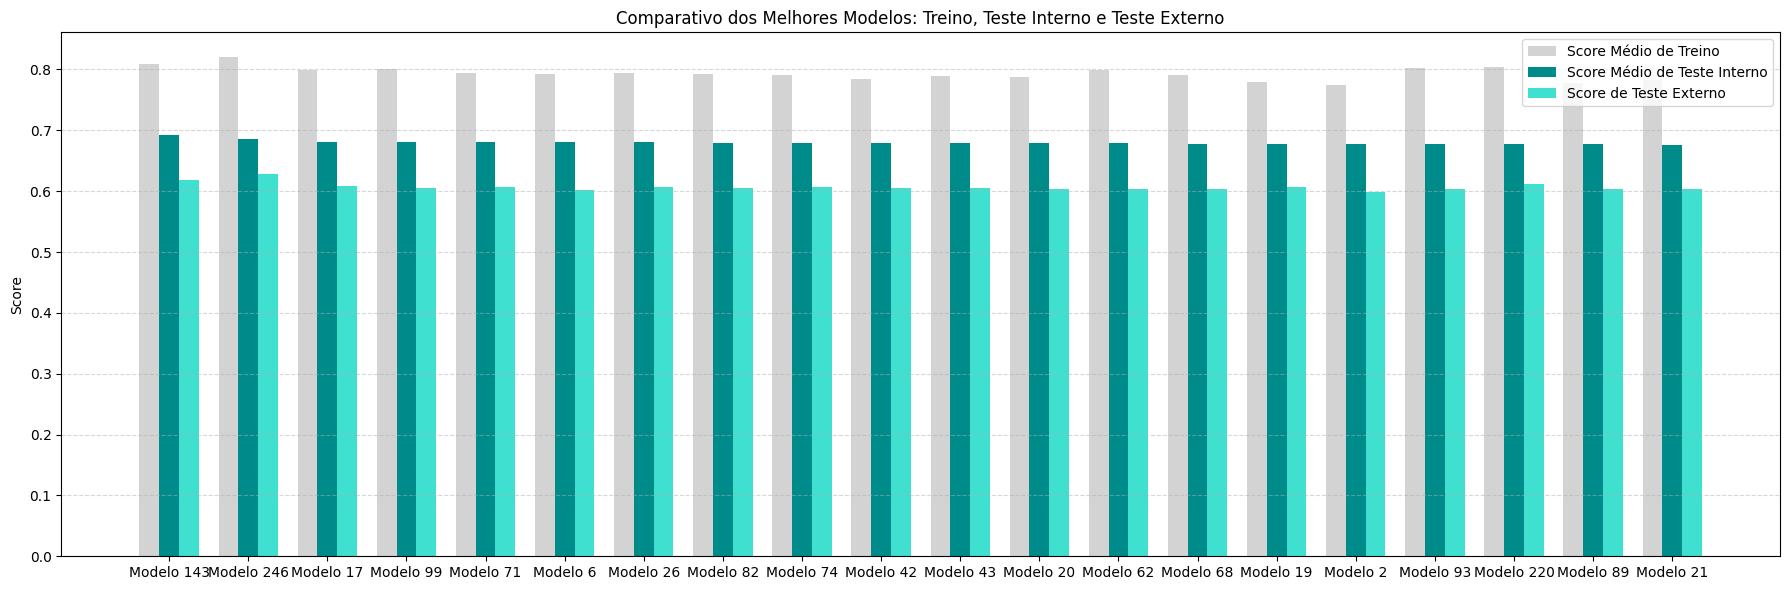

In [37]:
dados_grafico = resultados_filt_ord.head(20)     # Escolha quantos modelos quer exibir
x_pos = np.arange(len(dados_grafico))            # Posições dos rótulos do eixo X
largura_barra = 0.25                             # Largura das barras

plt.figure(figsize=(18, 6))
plt.bar(x_pos - largura_barra,                   # Série com score médio de treino
        dados_grafico["media_score_treino"],
        width=largura_barra,
        label="Score Médio de Treino",
        color="lightgray")
plt.bar(x_pos,                                   # Série com score médio de teste interno
        dados_grafico["media_score_teste_interno"],
        width=largura_barra,
        label="Score Médio de Teste Interno",
        color="darkcyan")
plt.bar(x_pos + largura_barra,                   # Série com score médio de teste externo
        dados_grafico["score_teste_externo"],
        width=largura_barra,
        label="Score de Teste Externo",
        color="turquoise")

plt.xticks(x_pos,
           dados_grafico["num_modelo"],
           rotation=0,
           ha='center')
plt.ylabel("Score")
plt.title("Comparativo dos Melhores Modelos: Treino, Teste Interno e Teste Externo")
plt.legend()
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

### **Etapa 7: Escolha do modelo**

*Escolha do modelo*

In [39]:
num_modelo_escolhido = "Modelo 143"

*Características do modelo escolhido*

In [40]:
linha = resultados.loc[resultados["num_modelo"] == num_modelo_escolhido].squeeze()
nome_algoritmo = linha["nome_algoritmo"]
hiperparametros = linha["hiperparametros"]
classe = algoritmos[nome_algoritmo][0]
print(f"O modelo final adotado foi construído com o algoritmo {nome_algoritmo}, com hiperparâmetros: { {k: round(v, 4) if isinstance(v, float) else v for k, v in hiperparametros.items()} }")

O modelo final adotado foi construído com o algoritmo XGBOOST, com hiperparâmetros: {'colsample_bytree': np.float64(0.8172), 'learning_rate': np.float64(0.005), 'max_depth': 3, 'n_estimators': 189, 'reg_alpha': np.float64(8.506), 'reg_lambda': np.float64(0.0047), 'subsample': np.float64(0.7898)}


In [45]:
# 1. Configurar o modelo com os melhores hiperparâmetros encontrados
modelo_final = classe.set_params(**hiperparametros)

# 2. Lógica de Ponderação (Para evitar aplicar peso duas vezes)
# Se for XGBoost, ele PRECISA dos pesos manuais no .fit()
if "XGB" in type(modelo_final).__name__:
    print(f"Detectado XGBoost: Calculando e aplicando sample_weights manuais...")
    pesos_treino = compute_sample_weight(class_weight='balanced', y=y_treino)
    modelo_final.fit(X_treino_tratada, y_treino, sample_weight=pesos_treino)

# Se for Random Forest ou LightGBM, eles já têm class_weight='balanced' embutido
else:
    print(f"Detectado {type(modelo_final).__name__}: Usando class_weight interno (sem sample_weight)...")
    # Verificação de segurança: Garantir que o parâmetro interno está ligado
    if hasattr(modelo_final, 'class_weight') and modelo_final.class_weight is None:
        modelo_final.set_params(class_weight='balanced')
        
    modelo_final.fit(X_treino_tratada, y_treino)

print("Modelo Final treinado com sucesso!")

Detectado XGBoost: Calculando e aplicando sample_weights manuais...
Modelo Final treinado com sucesso!


### **Etapa 8: Calibração e análises adicionais no conjunto de teste externo**

*Aplicação do modelo final no conjunto de teste externo*

In [47]:
p_hat_teste = modelo_final.predict_proba(X_teste_tratada)
classes = modelo_final.classes_

*Atribuição da categoria de resposta predita pelo modelo, com base na maior probabilidade*

In [48]:
y_hat_teste = classes[p_hat_teste.argmax(axis=1)]

*Verificação gráfica de calibração das probabilidades*

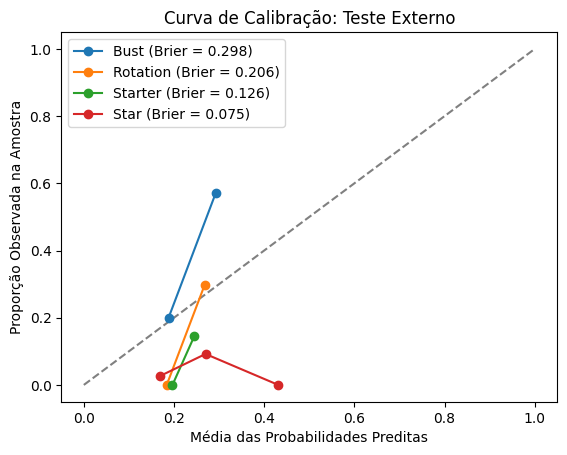

In [49]:
# Cálculos
y_one_hot = label_binarize(y_teste, classes=classes)

# Gráfico da curva de calibração para cada classe (one-versus-rest)
plt.plot([0,1],[0,1],'--', color='gray')
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    prop_obs, p_hat_media = calibration_curve(y_bin, p_hat_teste[:, k])
    brier = brier_score_loss(y_bin, p_hat_teste[:, k])
    plt.plot(p_hat_media,
             prop_obs,
             'o-',
             label=f"{ordem_categorias[cls]} (Brier = {brier:.3f})")
plt.xlabel("Média das Probabilidades Preditas")
plt.ylabel("Proporção Observada na Amostra")
plt.title("Curva de Calibração: Teste Externo")
plt.legend()
plt.show()

***(Se necessário)*** *Atualização de probabilidades preditas no teste, por meio de recalibração das probabilidades no conjunto de treino*

In [50]:
# Recalibração do modelo no treino - escolha o método: 'isotonic' (n > 1000) ou 'sigmoid'
modelo_final_calibrado = CalibratedClassifierCV(modelo_final, method='sigmoid', cv=5)
modelo_final_calibrado.fit(X_treino_tratada, y_treino)

# Armazenamento de probabilidades não calibradas e cálculo das probabilidades calibradas
p_hat_teste_nao_calibradas = p_hat_teste
p_hat_teste = modelo_final_calibrado.predict_proba(X_teste_tratada)

***(Se necessário)*** *Verificação gráfica de calibração das probabilidades - atualização pós calibração*

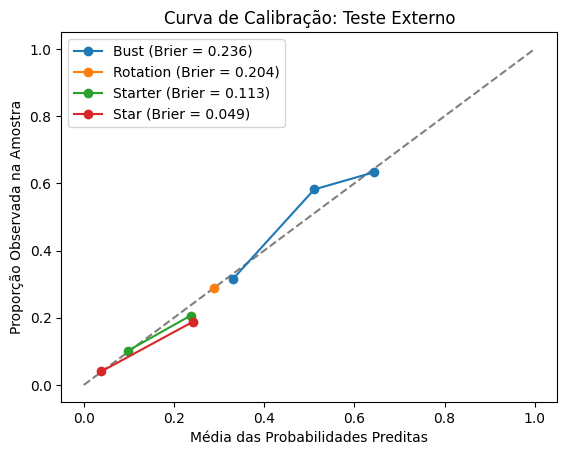

In [51]:
# Cálculos
y_one_hot = label_binarize(y_teste, classes=classes)

# Gráfico da curva de calibração para cada classe (one-versus-rest)
plt.plot([0,1],[0,1],'--', color='gray')
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    prop_obs, p_hat_media = calibration_curve(y_bin, p_hat_teste[:, k])
    brier = brier_score_loss(y_bin, p_hat_teste[:, k])
    plt.plot(p_hat_media,
             prop_obs,
             'o-',
             label=f"{ordem_categorias[cls]} (Brier = {brier:.3f})")
plt.xlabel("Média das Probabilidades Preditas")
plt.ylabel("Proporção Observada na Amostra")
plt.title("Curva de Calibração: Teste Externo")
plt.legend()
plt.show()

*Tabela de classificação*

In [52]:
# Tabela de classificação com frequências absolutas
tabela = pd.crosstab(y_teste, y_hat_teste)
tabela.index = np.asarray(ordem_categorias)[tabela.index]
tabela.columns = np.asarray(ordem_categorias)[tabela.columns]
tabela

,Bust,Rotation,Starter,Star
Bust,62,15,6,17
Rotation,27,7,13,8
Starter,7,6,6,7
Star,3,1,1,5


In [53]:
# Tabela de classificação com frequências relativas, somando 100% em cada linha
tabela_relativa_linhas = (tabela.div(tabela.sum(axis=1), axis=0)).round(3)
tabela_relativa_linhas

,Bust,Rotation,Starter,Star
Bust,0.620,0.150,0.060,0.170
Rotation,0.491,0.127,0.236,0.145
Starter,0.269,0.231,0.231,0.269
Star,0.300,0.100,0.100,0.500


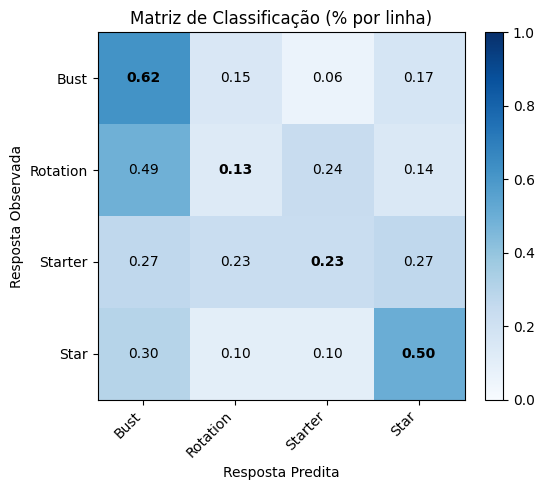

In [54]:
# Gráfico de calor com frequências relativas, somando 100% em cada linha
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_linhas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_linhas.shape[1]))
ax.set_yticks(range(tabela_relativa_linhas.shape[0]))
ax.set_xticklabels(tabela_relativa_linhas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_linhas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por linha)")

for (i, j), v in np.ndenumerate(tabela_relativa_linhas.values):
    same_label = tabela_relativa_linhas.index[i] == tabela_relativa_linhas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [55]:
# Tabela de classificação com frequências relativas, somando 100% em cada coluna
tabela_relativa_colunas = (tabela.div(tabela.sum(axis=0), axis=1)).round(3)
tabela_relativa_colunas

,Bust,Rotation,Starter,Star
Bust,0.626,0.517,0.231,0.459
Rotation,0.273,0.241,0.500,0.216
Starter,0.071,0.207,0.231,0.189
Star,0.030,0.034,0.038,0.135


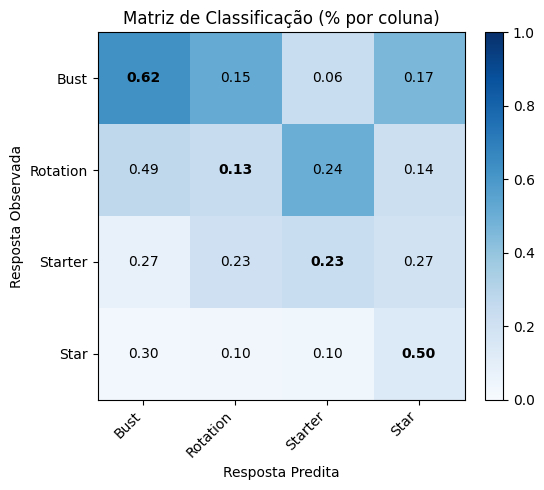

In [56]:
# Gráfico de calor com frequências relativas, somando 100% em cada coluna
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_colunas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_colunas.shape[1]))
ax.set_yticks(range(tabela_relativa_colunas.shape[0]))
ax.set_xticklabels(tabela_relativa_colunas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_colunas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por coluna)")

for (i, j), v in np.ndenumerate(tabela_relativa_linhas.values):
    same_label = tabela_relativa_linhas.index[i] == tabela_relativa_linhas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

*Desempenho: taxas de acerto por categoria, precisões por categoria, AUC-OVR, acurácia e acurácia balanceada*

In [57]:
# Taxas de acerto por categoria (recalls)
pd.Series(
    np.diag(tabela_relativa_linhas.reindex(columns=tabela_relativa_linhas.index).to_numpy()),
    index=tabela_relativa_linhas.index
)

Bust       0.620
Rotation   0.127
Starter    0.231
Star       0.500
dtype: float64

In [58]:
# Precisões por categoria
pd.Series(
    np.diag(tabela_relativa_colunas.reindex(columns=tabela_relativa_colunas.index).to_numpy()),
    index=tabela_relativa_colunas.index
)

Bust       0.626
Rotation   0.241
Starter    0.231
Star       0.135
dtype: float64

In [59]:
# AUC-OVR, acurácia e acurácia balanceada
auc_ovr = roc_auc_score(y_teste, p_hat_teste, multi_class='ovr', average='macro')
acuracia = accuracy_score(y_teste, y_hat_teste)
acuracia_balanceada = balanced_accuracy_score(y_teste, y_hat_teste)

print(f'AUC-OVR: {auc_ovr:.3f}')
print(f'Acurácia: {acuracia:.3f}')
print(f'Acurácia balanceada: {acuracia_balanceada:.3f}')

AUC-OVR: 0.629
Acurácia: 0.419
Acurácia balanceada: 0.370


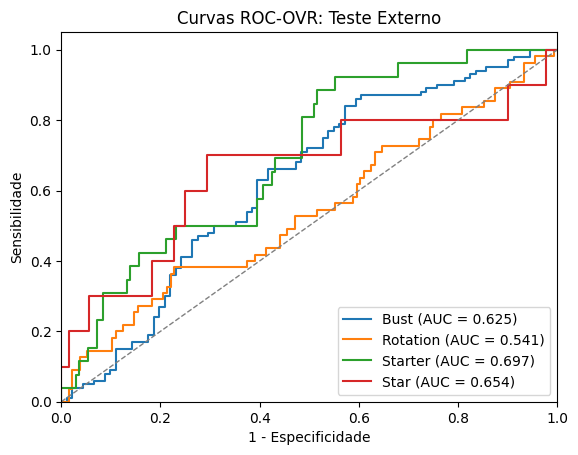

In [60]:
# Exibição das curvas ROC-OVR
plt.figure()
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    fpr, tpr, _ = roc_curve(y_bin, p_hat_teste[:, k])
    auc_k = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=1.5, label=f'{ordem_categorias[cls]} (AUC = {auc_k:.3f})')

plt.plot([0, 1], [0, 1], '--', color='gray', lw=1)
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel('1 - Especificidade'); plt.ylabel('Sensibilidade')
plt.title('Curvas ROC-OVR: Teste Externo')
plt.legend(loc="lower right")
plt.show()

### **Etapa 9: Interpretabilidade do modelo final**

*Cálculo da importância em redução de impureza para cada variável no modelo final (aplicável apenas para modelos baseados em árvores)*

In [61]:
# ATENÇÃO! Aplicável apenas caso o modelo final seja baseado em árvores, com exceção do gradient boosting com histogramas; caso contrário, resultará em erro
importancias_impureza = pd.Series(modelo_final.feature_importances_,
                                  index=X_treino_tratada.columns).sort_values()

*Gráfico de importâncias em redução de impureza (aplicável apenas para modelos baseados em árvores)*

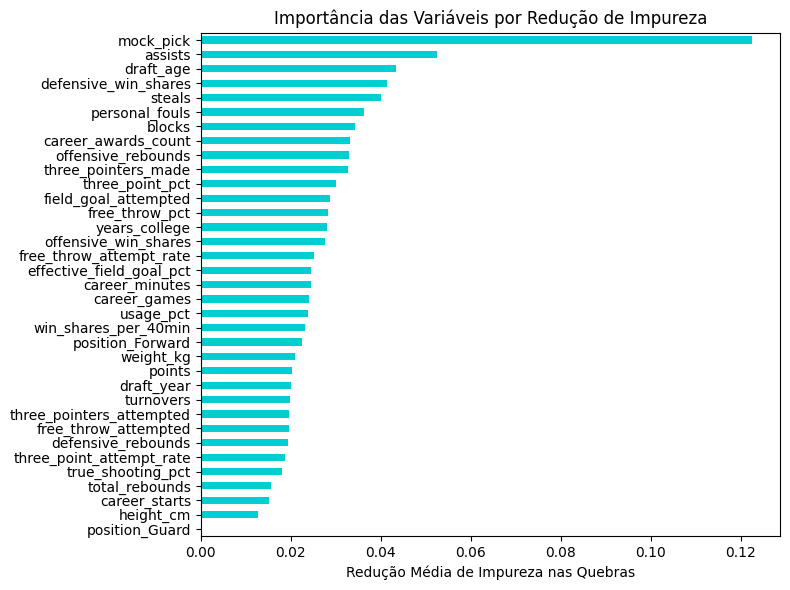

In [62]:
# ATENÇÃO! Aplicável apenas caso o modelo final seja baseado em árvores, com exceção do gradient boosting com histogramas; caso contrário, resultará em erro
plt.figure(figsize=(8, 6))
importancias_impureza.plot.barh(title="Importância das Variáveis por Redução de Impureza",
                                color="darkturquoise")
plt.xlabel("Redução Média de Impureza nas Quebras")
plt.tight_layout()
plt.show()

*Cálculo da importância por permutação para cada variável no modelo final*

In [63]:
importancias_permutacao = permutation_importance(modelo_final,
                                                 X_treino_tratada,
                                                 y_treino,
                                                 n_repeats=30,
                                                 random_state=123, 
                                                 scoring='roc_auc_ovr')
importancias_permutacao = pd.Series(importancias_permutacao.importances_mean,
                                    index=X_treino_tratada.columns).sort_values()

*Gráfico de importâncias por permutação*

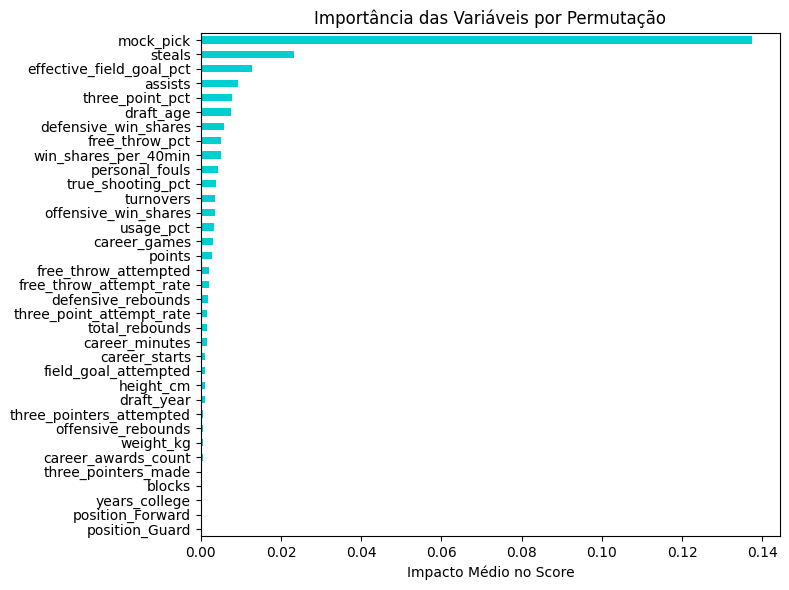

In [64]:
plt.figure(figsize=(8, 6))
importancias_permutacao.plot.barh(title="Importância das Variáveis por Permutação",
                                  color="darkturquoise")
plt.xlabel("Impacto Médio no Score")
plt.tight_layout()
plt.show()

*Cálculo dos valores SHAP das variáveis no modelo final*

In [65]:
if nome_algoritmo not in ['ADABOOST', 'GRADIENT BOOSTING', 'GRADIENT BOOSTING COM HISTOGRAMAS']:
    # Caso demore para rodar, especialmente em bases grandes, substitua X_treino_tratada.shape[0] por um número de tamanho de subamostra (ex.: 100)
    X_amostra = shap.sample(X_treino_tratada, X_treino_tratada.shape[0], random_state=123)
    explainer = shap.Explainer(modelo_final, X_amostra)
    valores_shap = explainer(X_amostra)
else:
    # Para AdaBoost, GB e GB com histogramas, a implementação do cálculo de valores SHAP no caso multinomial não é direta; é preciso usar um método mais oneroso computacionalmente, em uma subamostra pequena de observações
    X_amostra = shap.sample(X_treino_tratada, 100, random_state=123)
    explainer = shap.Explainer(modelo_final.predict_proba, X_amostra)
    valores_shap = explainer(X_amostra)

# Obs. Caso haja algum erro de atividade ("additivity"), acrescente o seguinte argumento na função 'explainer': check_additivity=False

 98%|===================| 3002/3052 [00:26<00:00]        

*Gráfico de valores absolutos médios de SHAP*

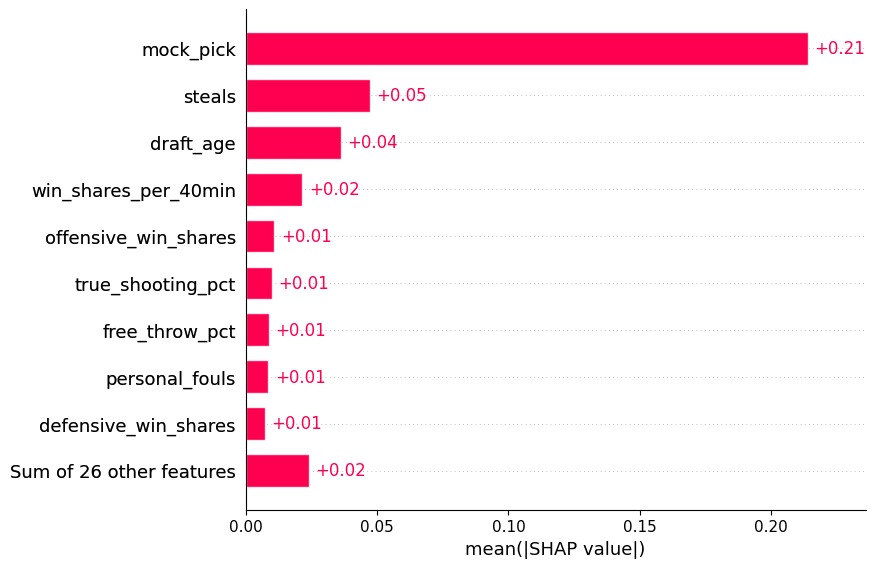

In [66]:
shap.plots.bar(valores_shap[:,:,0])    # ATENÇÃO: Altere o último valor dentro dos colchetes (0, 1, 2, ...) para alternar entras as diferentes categorias de resposta

*Gráfico de direção do impacto baseado em SHAP (beeswarm)*

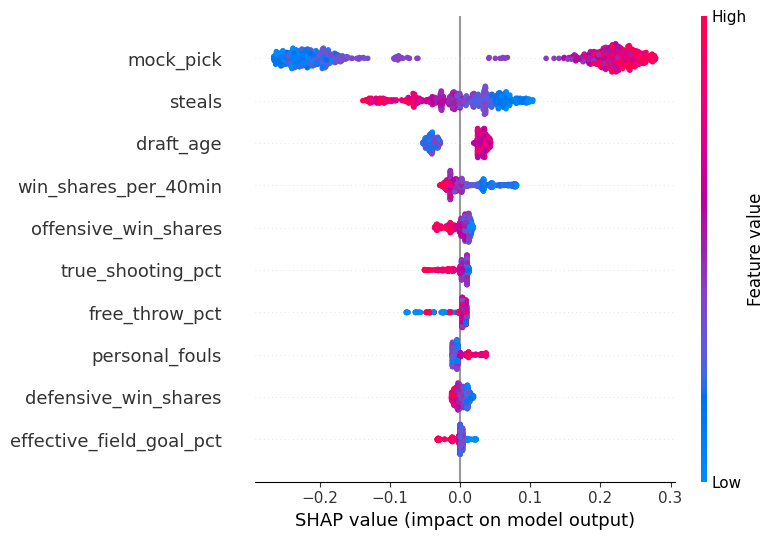

In [67]:
shap.summary_plot(valores_shap[:,:,0], max_display=10)    # ATENÇÃO: Altere o último valor dentro dos colchetes (0, 1, 2, ...) para alternar entras as diferentes categorias de resposta